# Compressing a trained image classifier

We start with a model that already knows how to classify images. We replace
three of its layers with smaller, factorized versions, using the weights it
has learned. We then measure what changed: storage, prediction accuracy, and
the time needed for a forward pass.

This notebook **runs the experiment**. We will load the model and images,
measure the dense baseline, call `compress_model`, and evaluate two compressed
copies. The tables and plots will use the measurements made in these cells.
There is no training or fine-tuning.

This saved copy was executed from a fresh kernel on the replayed 1,000-image
manifest. Its tables and plots show the measurements from that execution,
saved in `results/notebook_run_001/`. Colleagues can read these outputs without
repeating the experiment. To run it again, choose a new output directory, save
your edits, and execute all cells in order from a fresh example kernel.

## 1. Set up this run

Keep this file at `examples/model_compression/model_compression.ipynb` in the
feature checkout. It imports the loading, accuracy, and timing helpers from
the neighboring `experiment.py`. The model conversion itself stays visible
here.

Follow the [README setup instructions](README.md) for the isolated example
environment and select its **TensorLy model compression** kernel. This
notebook also uses Matplotlib for plots. Install it in that same environment
if needed; for the previously prepared environment, the terminal command is:

```bash
~/.cache/tltorch-model-compression/venv/bin/python -m pip install matplotlib==3.10.8
```

Provide the extracted **ImageNetV2 matched-frequency** dataset. Its archive is
about 1.26 GB, plus extraction space; the pretrained weights are about 45 MB.
Existing local images and cached weights are reused. Dataset downloads remain
an explicit setup step. Weight downloads are disabled below unless you opt in.
The README also links the authors' image-use guidance; the code's MIT license
does not cover the images.

In [1]:
import hashlib
import json
import os
import sys
from datetime import datetime, timezone
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import torch
from IPython.display import Markdown, display
from torchvision.models import ResNet18_Weights

# Support opening Jupyter from either the repository root or this notebook's folder.
example_directory = Path.cwd()
if not (example_directory / "experiment.py").is_file():
    example_directory = example_directory / "examples" / "model_compression"
if not (example_directory / "experiment.py").is_file():
    raise FileNotFoundError("Open this notebook from its folder or the repository root.")

example_directory = example_directory.resolve()
repository_root = example_directory.parents[1]
sys.path.insert(0, str(repository_root))

from tltorch import compress_model
from examples.model_compression import experiment

def show_table(columns, rows):
    """Display a small table without adding a dataframe dependency."""
    lines = [" | ".join(columns), " | ".join("---" for _ in columns)]
    lines.extend(" | ".join(str(value) for value in row) for row in rows)
    display(Markdown("\n".join(lines)))


The defaults below use the same quick comparison as the earlier experiment:
one image from each of 1,000 classes, evaluated on CPU in float32.
`batch_size` controls how many real images we evaluate together. Timing will
use a separate batch of one.

Each seed has one job: model loading/conversion, image selection, or synthetic
timing input. The same selected images and timing input will be reused for
every model.

Set `full=True` to evaluate all 10,000 images. To repeat an exact previous
selection, set `manifest_path` to its `selected_examples.json`; its size must
match `full`. Otherwise the selection seed chooses the images. Use a new
output directory for each run so previous measurements remain available.

In [2]:
cache_directory = Path.home() / ".cache" / "tltorch-model-compression"
os.environ.setdefault("TORCH_HOME", str(cache_directory / "torch"))

dataset_directory = Path(os.environ.get(
    "IMAGENETV2_DIR",
    str(cache_directory / "data" / "imagenetv2-matched-frequency-format-val"),
))
output_directory = example_directory / "results" / "notebook_run_001"
manifest_path = example_directory / "results" / "cpu_1000" / "selected_examples.json"

settings = {
    "device": "cpu",
    "threads": 4,
    "batch_size": 16,
    "workers": 0,
    "full": False,
    "seed": 2026,
    "selection_seed": 2026,
    "timing_seed": 2027,
    "warmup": 20,
    "repeats": 100,
    "allow_weight_download": False,
}

if output_directory.exists():
    raise FileExistsError(f"Choose a new results directory: {output_directory}")

device = experiment.configure_runtime(settings["device"], settings["threads"])
torch.manual_seed(settings["seed"])
environment = experiment.environment_info()
environment["packages"]["matplotlib"] = matplotlib.__version__

# Fingerprint the saved code cells; later output changes do not change this hash.
notebook_path = example_directory / "model_compression.ipynb"
notebook_on_disk = json.loads(notebook_path.read_text())
notebook_code = "\n\n".join(
    "".join(cell["source"])
    for cell in notebook_on_disk["cells"] if cell["cell_type"] == "code"
)
environment["notebook_code_sha256"] = hashlib.sha256(notebook_code.encode()).hexdigest()

print("Device:", device)
print("CPU:", environment["cpu"])
print("PyTorch threads:", environment["threads"])
print("TensorLy-Torch loaded from:", environment["tltorch_path"])
print("Results will be saved to:", output_directory)


Device: cpu
CPU: Intel(R) Core(TM) Ultra 9 285H
PyTorch threads: 4
TensorLy-Torch loaded from: /home/rafael_magaldi/Documents/infq-tensorly-torch-model-compression/tltorch/__init__.py
Results will be saved to: /home/rafael_magaldi/Documents/infq-tensorly-torch-model-compression/examples/model_compression/results/notebook_run_001


## 2. Load the trained model and evaluation images

Our baseline is torchvision **ResNet-18** with
`ResNet18_Weights.IMAGENET1K_V1`. These are already-trained weights; we do not
train a baseline ourselves.

The helper also returns that weight set's preprocessing. It resizes and crops
each image, converts it to a tensor, and normalizes its channels. Every model
will receive images prepared in exactly the same way.

We record a fingerprint of the baseline's parameters and buffers. Later we
will check it to confirm that conversion and evaluation left their values
unchanged. Model construction and compression happen outside inference mode;
the evaluation and timing helpers use inference mode for their forward passes.

In [3]:
baseline, preprocessing = experiment.load_baseline(
    device, allow_download=settings["allow_weight_download"]
)
baseline_fingerprint = experiment.model_fingerprint(baseline)

print("Model: ResNet-18")
print("Weights: ResNet18_Weights.IMAGENET1K_V1")
print(preprocessing)


Model: ResNet-18
Weights: ResNet18_Weights.IMAGENET1K_V1
ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


ImageNetV2 contains new images for the same 1,000 classes as the pretrained
model. We use real labeled images to measure accuracy.

The dataset's folder names are the labels: folder `"10"` means class 10.
The loader uses those numbers directly. Alphabetically assigning new indices
to the folders would give the wrong labels.

The selection helper checks the complete extracted release, sorts paths before
sampling, and records each selected image's path, label, and content hash.
It fails if required images are missing or a replayed image has changed.

In [4]:
manifest = experiment.select_examples(
    dataset_directory,
    seed=settings["selection_seed"],
    full=settings["full"],
    manifest_path=manifest_path,
)
batches = experiment.make_loader(
    dataset_directory,
    manifest,
    preprocessing,
    batch_size=settings["batch_size"],
    workers=settings["workers"],
    seed=settings["seed"],
)

print(f"Selected {len(manifest['examples']):,} real images.")
print("First three manifest entries:")
for example in manifest["examples"][:3]:
    print(f"  {example['path']} -> class {example['label']}")


Selected 1,000 real images.
First three manifest entries:
  0/64f661b97cfd6db73bd6c30325597cf7c7b322d5.jpeg -> class 0
  1/6dad81ab7e7b48efeb17b751a4e3ad716651c4fe.jpeg -> class 1
  2/f82eb5914602bb0bc538fc417ca3757949743eec.jpeg -> class 2


## 3. Measure the dense baseline

First, how well does the original model classify these images?

**Top-1 accuracy** asks whether its highest-scoring class is correct.
**Top-5 accuracy** asks whether the correct class appears among its five
highest-scoring classes. The helper counts correct predictions across all
examples, including a short final batch, before calculating percentages.

This is our measured ImageNetV2 baseline. We will compare compressed models
with this result, rather than with a published accuracy on another dataset.

In [5]:
baseline_accuracy = experiment.evaluate_accuracy(baseline, batches, device, progress=True)
measurements = {"dense": {"accuracy": baseline_accuracy}}

print(f"Images evaluated: {baseline_accuracy['examples']:,}")
print(f"Top-1: {baseline_accuracy['top1_percent']:.2f}%")
print(f"Top-5: {baseline_accuracy['top5_percent']:.2f}%")


  evaluated 160 images


  evaluated 320 images


  evaluated 480 images


  evaluated 640 images


  evaluated 800 images


  evaluated 960 images


Images evaluated: 1,000
Top-1: 56.80%
Top-5: 80.30%


Next, how long does one forward pass take?

The timing input has shape `(1, 3, 224, 224)`: one RGB image, 224 pixels high
and wide. It is a synthetic tensor already on the model's device. Synthetic
input is suitable for timing; it does not provide an accuracy measurement.

With the default settings, we warm up with 20 passes and time the next 100.
The helper uses evaluation and inference mode and synchronizes CUDA when
needed. Loading, conversion, preprocessing, and transfers are outside the
timer. All variants will use this same protocol and input.

Times are **milliseconds per batch of one**. The median is the middle sample;
the 25th and 75th percentiles describe the central half of this block's samples.

In [6]:
timing_generator = torch.Generator(device=device).manual_seed(settings["timing_seed"])
timing_input = torch.randn(
    1, 3, 224, 224,
    device=device,
    dtype=torch.float32,
    generator=timing_generator,
)
baseline_latency = experiment.measure_latency(
    baseline, timing_input, warmup=settings["warmup"], repeats=settings["repeats"]
)
measurements["dense"]["latency"] = baseline_latency

print(f"Median: {baseline_latency['median_ms']:.3f} ms")
print(f"Central half: {baseline_latency['p25_ms']:.3f}–{baseline_latency['p75_ms']:.3f} ms")


Median: 21.540 ms
Central half: 21.432–21.673 ms


## 4. Choose the layers and make the first compressed copy

We select two convolutions near the end of ResNet-18 and its final classifier.
The other layers keep their existing weights in the returned copy.

**Tucker** represents each selected convolution kernel with a smaller core
and factor matrices. `fixed_rank_modes="spatial"` keeps the spatial ranks at
the kernel's height and width; it still stores spatial factor matrices and
does not promise an exact kernel.

**BlockTT** represents the classifier matrix as a chain of tensor cores.
We split its 512 input features into `(8, 8, 8)` and its 1,000 outputs into
`(10, 10, 10)`. Each core carries one input/output mode pair. These tuples
describe the matrix dimensions; they are not convolution settings.

The first target is `0.75`: approximately 75% of each selected **weight's**
original parameter count. It is not a promise of 25% savings across the whole
model. Biases, unchanged layers, and rounding to integer ranks affect the
actual total. We will count the result.

**This dictionary is used by the conversion cell below.** Changing the selected
names or their options changes the conversion. The second copy will use the
same names and options with a smaller rank target.

In [7]:
first_fraction = 0.75

first_layers = {
    "layer4.0.conv2": {
        "factorization": "Tucker",
        "rank": first_fraction,
        "fixed_rank_modes": "spatial",
    },
    "layer4.1.conv2": {
        "factorization": "Tucker",
        "rank": first_fraction,
        "fixed_rank_modes": "spatial",
    },
    "fc": {
        "factorization": "BlockTT",
        "rank": first_fraction,
        "in_tensorized_features": (8, 8, 8),
        "out_tensorized_features": (10, 10, 10),
    },
}

for name in first_layers:
    layer = baseline.get_submodule(name)
    print(f"{name}: {type(layer).__name__}, weight shape {tuple(layer.weight.shape)}")


layer4.0.conv2: Conv2d, weight shape (512, 512, 3, 3)
layer4.1.conv2: Conv2d, weight shape (512, 512, 3, 3)
fc: Linear, weight shape (1000, 512)


Now we call the public API. It returns an independent model and a report.
The factors are initialized from the trained weights of `baseline`.

`implementation="factorized"` tells the new layers to carry out their forward
passes using the factors. The alternative, `"reconstructed"`, forms a dense
weight from those factors before applying the operation. Both use the
compressed approximation; reconstructing a weight does not restore information
discarded during compression. We use factorized execution throughout this run.

In [8]:
torch.manual_seed(settings["seed"])
compressed_model, first_report = compress_model(
    baseline, first_layers, implementation="factorized"
)
if experiment.model_fingerprint(baseline) != baseline_fingerprint:
    raise RuntimeError("The first conversion changed the dense baseline.")

for layer_report in first_report["replacements"]:
    name = layer_report["name"]
    replacement_type = type(compressed_model.get_submodule(name)).__name__
    print(f"{name} -> {replacement_type}; ranks {layer_report['actual_rank']}")


layer4.0.conv2 -> FactorizedConv; ranks (390, 390, 3, 3)
layer4.1.conv2 -> FactorizedConv; ranks (390, 390, 3, 3)
fc -> FactorizedLinear; ranks (1, 68, 68, 1)


## 5. Evaluate the first copy, then repeat with more compression

We use the same image loader and timing input as the baseline. The loader can
be iterated again: each pass visits the same selected images in the same order.
We save both measurements and the compression report before releasing this copy.

In [9]:
first_accuracy = experiment.evaluate_accuracy(compressed_model, batches, device, progress=True)
first_latency = experiment.measure_latency(
    compressed_model, timing_input,
    warmup=settings["warmup"], repeats=settings["repeats"],
)
measurements["compression_1"] = {"accuracy": first_accuracy, "latency": first_latency}
reports = {"compression_1": first_report}

print(f"Top-1: {first_accuracy['top1_percent']:.2f}%")
print(f"Top-5: {first_accuracy['top5_percent']:.2f}%")
print(f"Median latency: {first_latency['median_ms']:.3f} ms")

# The measurements and report remain available; release the model before the next copy.
del compressed_model


  evaluated 160 images


  evaluated 320 images


  evaluated 480 images


  evaluated 640 images


  evaluated 800 images


  evaluated 960 images


Top-1: 51.60%
Top-5: 76.10%
Median latency: 28.060 ms


The second target is `0.50`, approximately half the original parameter count
for each selected weight. We copy the settings above and change only `rank`.

Notice that `compress_model` receives **`baseline` again**. We do not compress
the first approximation a second time. Each result starts from the same trained
weights. We reset the conversion seed and repeat the same measurements.

In [10]:
second_fraction = 0.50
second_layers = {
    name: {**options, "rank": second_fraction}
    for name, options in first_layers.items()
}

torch.manual_seed(settings["seed"])
compressed_model, second_report = compress_model(
    baseline, second_layers, implementation="factorized"
)
if experiment.model_fingerprint(baseline) != baseline_fingerprint:
    raise RuntimeError("The second conversion changed the dense baseline.")

second_accuracy = experiment.evaluate_accuracy(compressed_model, batches, device, progress=True)
second_latency = experiment.measure_latency(
    compressed_model, timing_input,
    warmup=settings["warmup"], repeats=settings["repeats"],
)
measurements["compression_2"] = {"accuracy": second_accuracy, "latency": second_latency}
reports["compression_2"] = second_report
del compressed_model

final_baseline_fingerprint = experiment.model_fingerprint(baseline)
if final_baseline_fingerprint != baseline_fingerprint:
    raise RuntimeError("The experiment changed the dense baseline's parameters or buffers.")

print(f"Top-1: {second_accuracy['top1_percent']:.2f}%")
print(f"Top-5: {second_accuracy['top5_percent']:.2f}%")
print(f"Median latency: {second_latency['median_ms']:.3f} ms")
print("The dense baseline's parameters and buffers are unchanged.")


  evaluated 160 images


  evaluated 320 images


  evaluated 480 images


  evaluated 640 images


  evaluated 800 images


  evaluated 960 images


Top-1: 41.70%
Top-5: 69.60%
Median latency: 25.633 ms
The dense baseline's parameters and buffers are unchanged.


## 6. Inspect what the conversion produced

Before comparing task performance, inspect the actual representations. The
rank tuples come from the factors that were created, not just the requested
target. For Tucker, the four ranks describe output channels, input channels,
height, and width. For BlockTT, they describe the boundaries and internal
connections of its core chain.

**Relative weight error** measures the difference between the original weight
and the reconstructed compressed weight, divided by the original weight's norm.
The norm here is the square root of the sum of squared entries. A value of
0.2 is a weight-approximation measurement, not a 20% classification error rate.
Task accuracy comes from the images we evaluated.

In [11]:
variant_names = {
    "dense": "Dense baseline",
    "compression_1": "Compressed 1",
    "compression_2": "Compressed 2",
}
layers_by_variant = {"compression_1": first_layers, "compression_2": second_layers}

layer_rows = []
for variant, report in reports.items():
    for layer_report in report["replacements"]:
        relative_error = layer_report["weight_error"]["relative"]
        layer_rows.append([
            variant_names[variant],
            layer_report["name"],
            layer_report["requested_rank"],
            tuple(layer_report["actual_rank"]),
            f"{layer_report['original']['parameter_count']:,}",
            f"{layer_report['compressed']['parameter_count']:,}",
            "unavailable" if relative_error is None else f"{relative_error:.4f}",
        ])

show_table(
    ["Model", "Layer", "Requested rank", "Actual ranks",
     "Parameters before", "Parameters after", "Relative weight error"],
    layer_rows,
)


Model | Layer | Requested rank | Actual ranks | Parameters before | Parameters after | Relative weight error
--- | --- | --- | --- | --- | --- | ---
Compressed 1 | layer4.0.conv2 | 0.75 | (390, 390, 3, 3) | 2,359,296 | 1,768,278 | 0.3621
Compressed 1 | layer4.1.conv2 | 0.75 | (390, 390, 3, 3) | 2,359,296 | 1,768,278 | 0.1785
Compressed 1 | fc | 0.75 | (1, 68, 68, 1) | 513,000 | 381,800 | 0.4581
Compressed 2 | layer4.0.conv2 | 0.5 | (310, 310, 3, 3) | 2,359,296 | 1,182,358 | 0.4950
Compressed 2 | layer4.1.conv2 | 0.5 | (310, 310, 3, 3) | 2,359,296 | 1,182,358 | 0.2721
Compressed 2 | fc | 0.5 | (1, 56, 56, 1) | 513,000 | 260,840 | 0.6389

## 7. Compare the measurements

We now bring the measurements together. Storage comes directly from the
compression reports, including their `original` counts for the dense baseline.
We do not reconstruct weights to count their dense sizes or implement another
parameter counter.

The next cell only assembles rows for display and saving. It does not load old
result files, run any more forward passes, or change the models.

**Compressed 1** is the first conversion (the default target is 0.75).
**Compressed 2** is the second (the default target is 0.50). The per-layer
table above shows the ranks actually requested and produced.

In [12]:
rows = []
for variant, measurement in measurements.items():
    accuracy = measurement["accuracy"]
    if accuracy["examples"] != baseline_accuracy["examples"]:
        raise ValueError("Every model must be evaluated on the same number of images.")

    report = first_report if variant == "dense" else reports[variant]
    side = "original" if variant == "dense" else "compressed"
    row = {
        "variant": variant,
        **accuracy,
        "top1_change_pp": accuracy["top1_percent"] - baseline_accuracy["top1_percent"],
        "top5_change_pp": accuracy["top5_percent"] - baseline_accuracy["top5_percent"],
        **report["model"][side],
        "flops_total": None,
        "flops_reason": experiment.FLOPS["reason"],
    }
    for key, value in report["replaced_layers"][side].items():
        row[f"replaced_{key}"] = value
    for key in ("median_ms", "p25_ms", "p75_ms"):
        row[f"latency_{key}"] = measurement["latency"][key]
    rows.append(row)


**Accuracy.** Changes are percentage points relative to the dense baseline
measured above. For example, a change from 60% to 55% is a loss of 5 percentage
points. This comparison describes the immediate effect of compression, before
any fine-tuning.

In [13]:
show_table(
    ["Model", "Images", "Top-1 %", "Change (pp)", "Top-5 %", "Change (pp)"],
    [
        [variant_names[row["variant"]], row["examples"],
         f"{row['top1_percent']:.2f}", f"{row['top1_change_pp']:+.2f}",
         f"{row['top5_percent']:.2f}", f"{row['top5_change_pp']:+.2f}"]
        for row in rows
    ],
)


Model | Images | Top-1 % | Change (pp) | Top-5 % | Change (pp)
--- | --- | --- | --- | --- | ---
Dense baseline | 1000 | 56.80 | +0.00 | 80.30 | +0.00
Compressed 1 | 1000 | 51.60 | -5.20 | 76.10 | -4.20
Compressed 2 | 1000 | 41.70 | -15.10 | 69.60 | -10.70

**Storage.** The whole-model table includes unchanged layers. The selected-layer
table shows just the layers we chose, before and after conversion. Parameters
include biases and frozen parameters; registered buffers include values such
as BatchNorm's running statistics. Shared tensor objects are counted once.

Bytes mean tensor contents: elements multiplied by bytes per element. These
totals exclude activations, temporary tensors, gradients, optimizer state, and
allocator overhead. They do not measure peak GPU memory or checkpoint size.

In [14]:
for title, prefix in (("Whole model", ""), ("Selected layers", "replaced_")):
    display(Markdown(f"**{title}**"))
    show_table(
        ["Model", "Parameters", "Parameter bytes", "Buffer bytes"],
        [
            [variant_names[row["variant"]],
             f"{row[prefix + 'parameter_count']:,}",
             f"{row[prefix + 'parameter_bytes']:,}",
             f"{row[prefix + 'buffer_bytes']:,}"]
            for row in rows
        ],
    )


**Whole model**

Model | Parameters | Parameter bytes | Buffer bytes
--- | --- | --- | ---
Dense baseline | 11,689,512 | 46,758,048 | 38,560
Compressed 1 | 10,376,276 | 41,505,104 | 38,560
Compressed 2 | 9,083,476 | 36,333,904 | 38,560

**Selected layers**

Model | Parameters | Parameter bytes | Buffer bytes
--- | --- | --- | ---
Dense baseline | 5,231,592 | 20,926,368 | 0
Compressed 1 | 3,918,356 | 15,673,424 | 0
Compressed 2 | 2,625,556 | 10,502,224 | 0

**Latency.** Compare these timings under the recorded hardware and settings.
Smaller factors can require more separate operations, so fewer stored
parameters do not guarantee a faster forward pass.

There is a known limitation in the earlier CPU measurements for this PR:
separate runs produced dense medians of about 20.71 ms and 10.91 ms. Three
fresh-process follow-ups did not explain the discrepancy or reproduce 10.91 ms.
The [README](README.md) and [follow-up records](results/timing_followup/) retain
that evidence. The table below contains **this notebook run's measurements**.
Its quartiles describe variation within each timing block; they do not establish
stability across separate runs or a dependable speedup/slowdown ratio.

In [15]:
show_table(
    ["Model", "Median ms", "25th percentile ms", "75th percentile ms"],
    [
        [variant_names[row["variant"]], f"{row['latency_median_ms']:.3f}",
         f"{row['latency_p25_ms']:.3f}", f"{row['latency_p75_ms']:.3f}"]
        for row in rows
    ],
)
print("Units: milliseconds per batch of one; warm-up and transfers excluded.")


Model | Median ms | 25th percentile ms | 75th percentile ms
--- | --- | --- | ---
Dense baseline | 21.540 | 21.432 | 21.673
Compressed 1 | 28.060 | 27.898 | 28.254
Compressed 2 | 25.633 | 25.490 | 25.830

Units: milliseconds per batch of one; warm-up and transfers excluded.


## 8. Plot and interpret this run

The first two panels compare whole-model parameter storage and top-1 accuracy.
One MiB is `2**20` bytes. The timing panel uses every recorded pass: each box
spans the 25th to 75th percentiles, its line is the median, and its whiskers
show the minimum and maximum. These are observed samples, not confidence intervals.

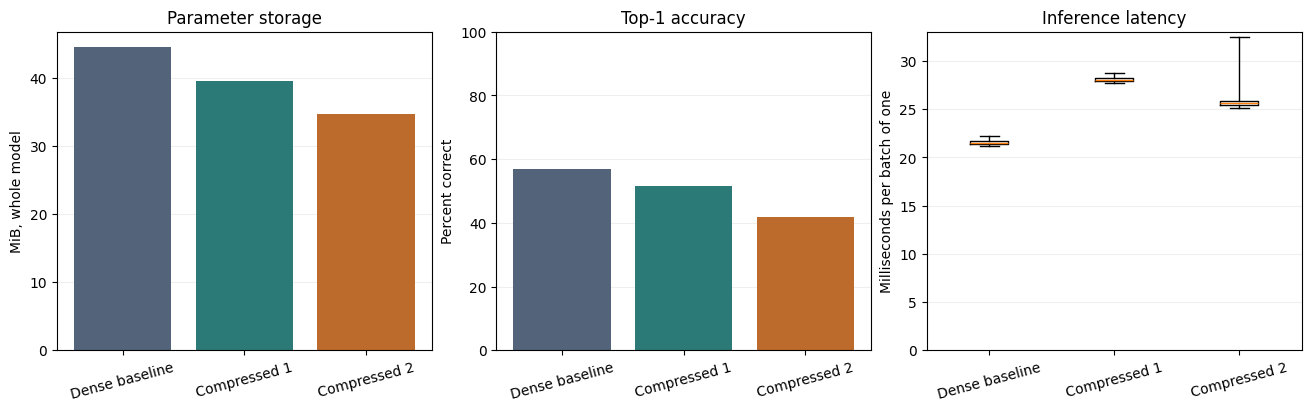

In [16]:
labels = [variant_names[row["variant"]] for row in rows]
positions = list(range(len(rows)))
colors = ["#52637a", "#2c7a78", "#bc6b2c"]

figure, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
axes[0].bar(positions, [row["parameter_bytes"] / 2**20 for row in rows], color=colors)
axes[0].set_title("Parameter storage")
axes[0].set_ylabel("MiB, whole model")

axes[1].bar(positions, [row["top1_percent"] for row in rows], color=colors)
axes[1].set_title("Top-1 accuracy")
axes[1].set_ylabel("Percent correct")
axes[1].set_ylim(0, 100)

timing_samples = [measurements[row["variant"]]["latency"]["samples_ms"] for row in rows]
axes[2].boxplot(timing_samples, positions=positions, whis=(0, 100), showfliers=False)
axes[2].set_title("Inference latency")
axes[2].set_ylabel("Milliseconds per batch of one")
axes[2].set_ylim(bottom=0)

for axis in axes:
    axis.set_xticks(positions, labels, rotation=15)
    axis.grid(axis="y", alpha=0.2)
    axis.set_axisbelow(True)
plt.show()


How much of the model did we actually save, and what accuracy change came
with it? The next cell calculates those two quantities from this run.
It makes no assumption that either target will preserve accuracy or improve speed.

In [17]:
original_bytes = first_report["model"]["original"]["parameter_bytes"]
for row in rows[1:]:
    saved_bytes = original_bytes - row["parameter_bytes"]
    saving_percent = 100 * saved_bytes / original_bytes
    print(
        f"{variant_names[row['variant']]}: {saving_percent:+.1f}% parameter-storage saving; "
        f"top-1 change {row['top1_change_pp']:+.2f} percentage points."
    )


Compressed 1: +11.2% parameter-storage saving; top-1 change -5.20 percentage points.
Compressed 2: +22.3% parameter-storage saving; top-1 change -15.10 percentage points.


Read the storage, accuracy, and timing results together. A useful setting for
one deployment may be unacceptable for another. These two targets do not
identify the best ranks or predict what fine-tuning would recover.

With the quick selection, the accuracy result describes these 1,000 images.
Use `full=True` for the full 10,000-image evaluation. A run on one CPU does not
establish GPU performance, and timing differences should be checked in fresh
runs before making a deployment claim.

**FLOP totals remain unavailable.** We have not established a counting method
that covers the factorized contractions. We record that limitation instead of
presenting an incomplete total as a complete count.

## 9. Save the measurements and the setup that produced them

Save enough information for someone else to repeat the comparison: the image
selection, actual layer settings, weights, preprocessing, seeds, environment,
and all timing samples. The layer dictionaries saved here are the ones passed
to `compress_model`, including any edits you made.

The environment record includes package versions, hardware and backend
settings, the Git revision and working-tree status, and code fingerprints.
Per-image hashes identify the evaluated data. We do not claim to have checked
a dataset archive in this notebook; it uses the extracted images directly.

In [18]:
weights = ResNet18_Weights.IMAGENET1K_V1
weight_file = Path(torch.hub.get_dir()) / "checkpoints" / weights.url.rsplit("/", 1)[-1]

configuration = {
    "settings": {
        **settings,
        "dataset": str(dataset_directory.resolve()),
        "output": str(output_directory),
        "manifest": str(manifest_path) if manifest_path is not None else None,
        "selection_seed": manifest["seed"],
        "evaluation_size": len(manifest["examples"]),
    },
    "environment": environment,
    "model": "torchvision.resnet18",
    "weights": {
        "identifier": "ResNet18_Weights.IMAGENET1K_V1",
        "url": weights.url,
        "sha256": experiment.file_sha256(weight_file),
    },
    "preprocessing": {
        "description": str(preprocessing),
        "color_mode": "RGB",
        "resize_size": preprocessing.resize_size,
        "crop_size": preprocessing.crop_size,
        "mean": preprocessing.mean,
        "std": preprocessing.std,
        "interpolation": str(preprocessing.interpolation),
        "antialias": preprocessing.antialias,
    },
    "dataset": {
        "release": manifest["dataset"],
        "reference_download_url": experiment.DATASET_URL,
        "hosting_revision": experiment.DATASET_REVISION,
        "archive_sha256": None,
        "selected_image_checksums": "SHA-256 for each image in selected_examples.json",
    },
    "layers": layers_by_variant,
    "variant_labels": variant_names,
    "implementation": "factorized",
    "dtype": str(timing_input.dtype),
    "timing_input_shape": list(timing_input.shape),
    "timing_units": "milliseconds per batch",
    "measurement_order": list(measurements),
    "baseline_fingerprint_before": baseline_fingerprint,
    "baseline_fingerprint_after": final_baseline_fingerprint,
    "flops": experiment.FLOPS,
    "completed_utc": datetime.now(timezone.utc).isoformat(),
}


These small files keep the measurements usable without a notebook or dashboard:

| File | What it contains |
| --- | --- |
| `results.csv` | Accuracy, storage, and timing summaries for each model. |
| `compression_reports.json` | Per-layer ranks, storage, weight errors, and totals. |
| `measurements.json` | Accuracy counts and full-precision timing measurements. |
| `latency_samples.json` | Every recorded timing sample. |
| `selected_examples.json` | Image paths, integer labels, and content hashes. |
| `configuration.json` | The actual settings and environment for this run. |
| `comparison.png` | The three plots above. |

The final cell creates a new directory and refuses to overwrite an existing
run. CSV formatting rounds displayed percentages and times; the JSON records
retain the measured values. Images, weights, and the Python environment stay
outside the repository. After this cell finishes, save the notebook to retain
its explanations, tables, and plot outputs alongside these separate files.

In [19]:
output_directory.mkdir(parents=True, exist_ok=False)
experiment.write_csv(output_directory / "results.csv", rows)

artifacts = {
    "configuration.json": configuration,
    "selected_examples.json": manifest,
    "compression_reports.json": reports,
    "measurements.json": measurements,
    "latency_samples.json": {
        name: measurement["latency"]["samples_ms"]
        for name, measurement in measurements.items()
    },
}
for filename, contents in artifacts.items():
    (output_directory / filename).write_text(
        json.dumps(contents, indent=2, allow_nan=False) + "\n",
        encoding="utf-8",
    )
figure.savefig(output_directory / "comparison.png", dpi=160, bbox_inches="tight")

print("Saved this run to:", output_directory)
print("Save the executed notebook now to keep its visible outputs as well.")


Saved this run to: /home/rafael_magaldi/Documents/infq-tensorly-torch-model-compression/examples/model_compression/results/notebook_run_001
Save the executed notebook now to keep its visible outputs as well.
